## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

# 1. Read data (Now it is the same data)

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/groups_retrain_single_allele_balanced_data/" #!CHANGE
APPROACH = "DECOY_PATHS"

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
          ]
ALLELES = [
    'HLA-A*01:01',
    'HLA-A*03:01',
    # 'HLA-A*02:01б'
   'HLA-DRB1*01:01'
          ]
selected_alleles = ALLELES
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-DRB1*01:01']

## 2.0 Merge alleles together

In [4]:
# combination_size = len(ALLELES)
ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'])
# ALLELES = sorted([ 'HLA-A*03:01'])

ALLELES = sorted(['HLA-DRB1*01:01'])


combination_size = 1
TOTAL_SPLITS = 1
TARGET_LENGTHS= [10, 11, 12,13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]
RUNS = 5
USE_WEIGHTS = True

# SELECTED_RUN = 0
# SELECTED_RUN = {0,1,2,3,4,5, 6, 7, 8, 9}
SELECTED_RUN = {0,1}

# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0
models_to_read = ['bw']

In [5]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DRB1*01:01
Length 8: HLA-DRB1*01:01 - 39 
Length 9: HLA-DRB1*01:01 - 113 
Length 10: HLA-DRB1*01:01 - 123 
Length 11: HLA-DRB1*01:01 - 175 
Length 12: HLA-DRB1*01:01 - 368 
Length 13: HLA-DRB1*01:01 - 826 
Length 14: HLA-DRB1*01:01 - 1184 
Length 15: HLA-DRB1*01:01 - 6886 
Length 16: HLA-DRB1*01:01 - 1413 
Length 17: HLA-DRB1*01:01 - 984 
Length 18: HLA-DRB1*01:01 - 708 
Length 19: HLA-DRB1*01:01 - 316 
Length 20: HLA-DRB1*01:01 - 505 
Length 21: HLA-DRB1*01:01 - 177 
Length 22: HLA-DRB1*01:01 - 80 
Length 23: HLA-DRB1*01:01 - 57 
Length 24: HLA-DRB1*01:01 - 67 
Length 25: HLA-DRB1*01:01 - 50 
Length 26: HLA-DRB1*01:01 - 15 
Length 27: HLA-DRB1*01:01 - 12 
Length 28: HLA-DRB1*01:01 - 8 
Length 30: HLA-DRB1*01:01 - 7 


## Calculate weights for data

In [6]:
TARGET_LENGTHS

[10, 11, 12, 13, 14, 15, 16, 17, 18]

In [7]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [8]:
per_allele_per_kfold_per_length_weights = \
    calculate_weights_based_on_length_counts(count_df_train,
                                             selected_alleles=ALLELES,
                                             total_splits=TOTAL_SPLITS,
                                             selected_lengths=TARGET_LENGTHS,
                                             use_weights=USE_WEIGHTS)

Total data length for split 0 is 12667
Weights for lentgh 10 are {'HLA-DRB1*01:01': 102.98373983739837}
Weights for lentgh 11 are {'HLA-DRB1*01:01': 72.38285714285715}
Weights for lentgh 12 are {'HLA-DRB1*01:01': 34.421195652173914}
Weights for lentgh 13 are {'HLA-DRB1*01:01': 15.335351089588377}
Weights for lentgh 14 are {'HLA-DRB1*01:01': 10.69847972972973}
Weights for lentgh 15 are {'HLA-DRB1*01:01': 1.83952948010456}
Weights for lentgh 16 are {'HLA-DRB1*01:01': 8.964614295824488}
Weights for lentgh 17 are {'HLA-DRB1*01:01': 12.872967479674797}
Weights for lentgh 18 are {'HLA-DRB1*01:01': 17.891242937853107}


In [9]:
count_df_train

cnt
allele         split length      
HLA-DRB1*01:01 0     8         39
                     9        113
                     10       123
                     11       175
                     12       368
                     13       826
                     14      1184
                     15      6886
                     16      1413
                     17       984
                     18       708
                     19       316
                     20       505
                     21       177
                     22        80
                     23        57
                     24        67
                     25        50
                     26        15
                     27        12
                     28         8
                     30         7

# Read models

In [10]:
MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10, 11, 12]
    },
    "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },

        "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },

    "multiple_allele_balanced_longer_training": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "100-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },

    "groups_retrain_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/",
        "states": 45,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]}
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [11]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['single_allele_imbalanced', 'single_allele_balanced', 'multiple_allele_balanced', 'single_allele_balanced_class2', 'single_allele_balanced_class2_biger', 'multiple_allele_imbalanced', 'multiple_allele_balanced_longer_training', 'mix_of_alleles', 'groups_retrain_single_allele_balanced_data'])

In [12]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
    # "single_allele_balanced_class2",
        "groups_retrain_single_allele_balanced_data"
    # 'multiple_allele_balanced_longer_training'
]


In [13]:
from hmm_logic_methods import load_model

In [14]:
import itertools
import mhcnames

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    model_alleles = set(model_alleles).intersection(set(ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [15]:
list(per_name_binding_model.keys())

['0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0']

## 2.2 Train
### 2.2.1 Define treshold

In [16]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -100 / 9
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

11.744135802469136

In [17]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix

per_model_total_df = dict()

for model_key, model in per_name_binding_model.items():
    per_state_information = dict()
    per_state_distribution = dict()
    per_level_information = defaultdict(float)

    for state in model.states:
        if state not in [model.start, model.end]:
            info_matrix = probs_to_info_matrix(state.distribution)
            per_state_distribution[state.name] = state.distribution.parameters[0]
            per_state_information[state.name] = sum(info_matrix.loc[0])
            # per_level_information[name_to_level[state.name]] += per_state_information[state.name]
    info_df = pd.DataFrame(per_state_information.items(), columns=["state", "info"])
    distr_df = pd.DataFrame(per_state_distribution.values())
    total_df = pd.concat([info_df, distr_df], axis=1)
    per_model_total_df[model_key] = total_df

In [18]:
filtered_dfs = list()
per_model_important_states = dict()

for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
    total_df = total_df.sort_values(by='info', ascending=False).copy()
    total_df = total_df[total_df['info'] > 1.2]
    total_df['model'] = i
    total_df['model_name'] = model_key
    filtered_dfs.append(total_df)
    per_model_important_states[model_key] = list(total_df['state'].values)



In [19]:
filtered_dfs[0]

,state,info,A,C,D,E,F,G,H,I,...,P,Q,R,S,T,V,W,Y,model,model_name
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.171099,0.003155,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.004394,0.001339,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.001008,0.000178,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.156395,0.004475,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.000037,0.069623,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.014653,0.029949,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.000497,0.008310,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.017600,0.100528,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.000973,0.017620,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.000250,0.087229,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...


In [20]:
total_df = pd.concat(filtered_dfs)

In [21]:
total_df[total_df['model'] == 0]

,state,info,A,C,D,E,F,G,H,I,...,P,Q,R,S,T,V,W,Y,model,model_name
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.171099,0.003155,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.004394,0.001339,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.001008,0.000178,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.156395,0.004475,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.000037,0.069623,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.014653,0.029949,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.000497,0.008310,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.017600,0.100528,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.000973,0.017620,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.000250,0.087229,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...


In [22]:
values_to_run_pca_on = total_df.drop(columns=['state', 'info', 'model', 'model_name'])

In [23]:
values_to_run_pca_on

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
27,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,0.000080,0.001025,0.001799,0.009395,0.171099,0.003155,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439
29,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,0.000212,0.007819,0.000314,0.077943,0.004394,0.001339,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346
14,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,0.000076,0.108494,0.016394,0.000120,0.001008,0.000178,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210
25,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,0.000314,0.031942,0.001637,0.066315,0.156395,0.004475,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095
20,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,0.000083,0.438666,0.109198,0.010665,0.000037,0.069623,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402
38,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,0.000577,0.404053,0.027598,0.002137,0.014653,0.029949,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962
10,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,0.000421,0.242141,0.016629,0.000613,0.000497,0.008310,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371
28,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,0.002364,0.011702,0.002268,0.016258,0.017600,0.100528,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646
40,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,0.346873,0.129738,0.019605,0.000283,0.000973,0.017620,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088
17,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,0.000488,0.413889,0.024291,0.013238,0.000250,0.087229,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401


In [24]:
from sklearn.decomposition import PCA

# overwrite for non-linear test
def get_pca(df_concat, n_components=2, whiten=True):
    pca = PCA(n_components=n_components, whiten=whiten)
    X = df_concat.values
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

In [25]:
pca = get_pca(values_to_run_pca_on)

Shape (52, 20)
Explained variation per principal component: [0.34706406 0.1955399 ]


In [26]:
pca_result = pca.transform(values_to_run_pca_on.values)

In [27]:
total_df[['pca0', 'pca1']] = pca_result

In [28]:
total_df

,state,info,A,C,D,E,F,G,H,I,...,R,S,T,V,W,Y,model,model_name,pca0,pca1
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.592955,0.027389
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.460303,-0.416681
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.939126,2.113840
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.294711,-0.428126
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.979130,-1.300596
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.515607,-1.250732
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.924765,0.234386
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,0.218467,0.605204
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,0.137810,0.166010
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.801975,-0.891005


In [29]:
from sklearn.cluster import KMeans

clustering = KMeans().fit(values_to_run_pca_on)
clustering.labels_

array([2, 3, 1, 3, 5, 0, 0, 6, 4, 0, 6, 3, 1, 1, 2, 3, 5, 0, 0, 0, 0, 1,
       4, 3, 5, 1, 2, 2, 3, 4, 1, 0, 2, 3, 5, 1, 1, 0, 5, 7, 4, 6, 3, 5,
       1, 2, 0, 4, 6, 4, 1, 4])

In [30]:
# from sklearn.cluster import MeanShift
#
# clustering = MeanShift(bandwidth=0.3).fit(values_to_run_pca_on)
# clustering.labels_

<AxesSubplot:xlabel='pca0', ylabel='pca1'>

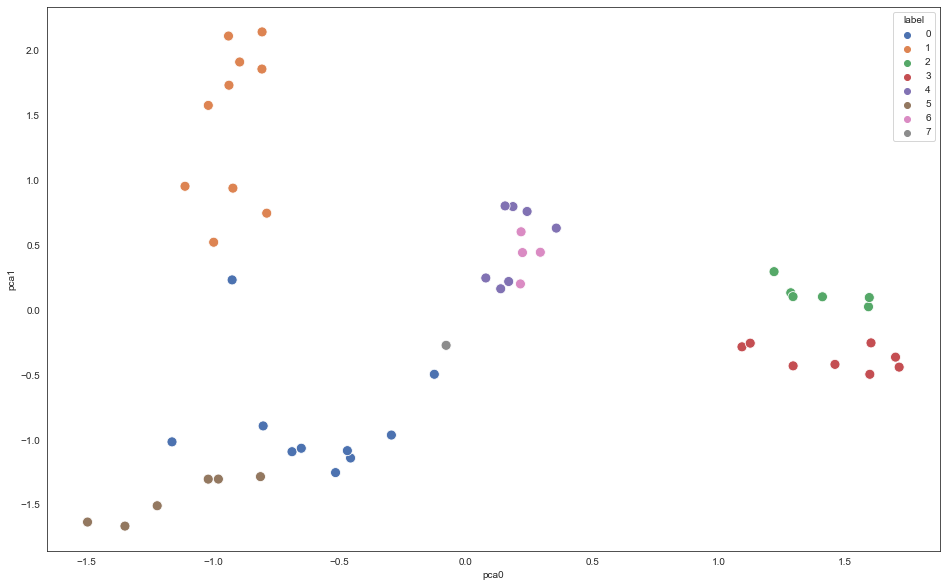

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
total_df['label'] = clustering.labels_
sns.scatterplot(data=total_df, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

In [32]:
total_df

,state,info,A,C,D,E,F,G,H,I,...,S,T,V,W,Y,model,model_name,pca0,pca1,label
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.592955,0.027389,2
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.460303,-0.416681,3
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.939126,2.113840,1
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.294711,-0.428126,3
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.979130,-1.300596,5
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.515607,-1.250732,0
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.924765,0.234386,0
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,0.218467,0.605204,6
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,0.137810,0.166010,4
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.801975,-0.891005,0


In [33]:
temp_df= total_df.drop(columns=['pca0', 'pca1', 'model', 'info', 'state'])


In [34]:
labels_to_distr = temp_df.groupby('label').mean()

In [35]:
pd.DataFrame(labels_to_distr.loc[0]).T

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.113224,0.008762,0.005265,0.007782,0.029858,0.05229,0.004899,0.090826,0.002517,0.355666,0.023397,0.005513,0.004132,0.020087,0.003726,0.030538,0.049141,0.160326,0.0155,0.01655


In [36]:
clustering.labels_

array([2, 3, 1, 3, 5, 0, 0, 6, 4, 0, 6, 3, 1, 1, 2, 3, 5, 0, 0, 0, 0, 1,
       4, 3, 5, 1, 2, 2, 3, 4, 1, 0, 2, 3, 5, 1, 1, 0, 5, 7, 4, 6, 3, 5,
       1, 2, 0, 4, 6, 4, 1, 4])

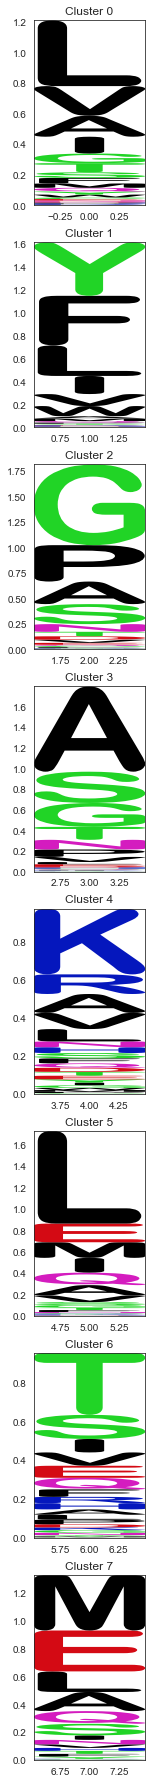

In [37]:
unique_labels = set(clustering.labels_)
fig, axes = plt.subplots(ncols=1, nrows=len(unique_labels), figsize=(2, len(unique_labels) * 4))

for label in unique_labels:
    # dummy_df = pd.DataFrame(columns = sorted(amino_acids), index = [0],  dtype=float)
    dummy_df = pd.DataFrame(labels_to_distr.loc[label]).T
    dummy_df.index.name = "pos"
    # for i, (acid, prob) in enumerate(state.distribution.parameters[0].items()):
    #     dummy_df.loc[0, acid] = prob

    # return dummy_df
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    ww_logo = logomaker.Logo(info_matrix,ax=axes[label],

                             font_name='Arial Rounded MT Bold',
                             #stack_order='small_on_top'
                             )
    ww_logo.ax.set_title(f"Cluster {label}")

In [38]:
per_state_number_group = {i: i // 5 for i in range(45)}
per_state_number_group

{0: 0,
 1: 0,
 2: 0,
 3: 0,
 4: 0,
 5: 1,
 6: 1,
 7: 1,
 8: 1,
 9: 1,
 10: 2,
 11: 2,
 12: 2,
 13: 2,
 14: 2,
 15: 3,
 16: 3,
 17: 3,
 18: 3,
 19: 3,
 20: 4,
 21: 4,
 22: 4,
 23: 4,
 24: 4,
 25: 5,
 26: 5,
 27: 5,
 28: 5,
 29: 5,
 30: 6,
 31: 6,
 32: 6,
 33: 6,
 34: 6,
 35: 7,
 36: 7,
 37: 7,
 38: 7,
 39: 7,
 40: 8,
 41: 8,
 42: 8,
 43: 8,
 44: 8}

In [39]:
total_df[total_df['label'] == label]

,state,info,A,C,D,E,F,G,H,I,...,S,T,V,W,Y,model,model_name,pca0,pca1,label
21,s021,1.33194,0.103374,0.001324,0.000396,0.220959,0.014506,0.000671,0.016127,0.024368,...,0.062678,0.01612,0.019243,0.000551,0.012362,3,3_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.078174,-0.269867,7


## First let's try to simplify paths just marking selected states

In [53]:
filtered_dfs = list()
per_model_important_states = dict()

for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
    total_df = total_df.sort_values(by='info', ascending=False).copy()
    total_df = total_df[total_df['info'] > 1.2]
    total_df['model'] = i
    total_df['model_name'] = model_key
    filtered_dfs.append(total_df)
    per_model_important_states[model_key] = list(total_df['state'].values)



In [54]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4):
    print(f"Model {model.name}")
    model_graph = model.graph
    print("Get viterbi paths for each peptide...")

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_simplified_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        # result_simplified_paths.append(">".join(["AL" if node.name in per_model_important_states[model.name] else "NA" for node in path_nodes[1:]]))
        result_simplified_paths.append(np.array([1 if node.name in per_model_important_states[model.name] else 0 for node in path_nodes[1:]]))

        count_al = [i for i,node in enumerate(path_nodes[1:]) if node.name in per_model_important_states[model.name]  ]
        start_core = count_al[0] if len(count_al) > 0 else np.nan
        end_core = count_al[-1] if len(count_al) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths,
         "simplified_path": result_simplified_paths,
         "core_start": result_start_core, "core_end": result_end_core,
         "prob": result_probs, "normalized_prob": result_normalized_probs, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df

In [55]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


total_df = pd.DataFrame(index=allele_peptides)
for i, (model_key, model) in enumerate(per_name_binding_model.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides)
    if 'simplified_path' not in total_df.columns:
        total_df['simplified_path'] = viterbi_paths['simplified_path'].values
    else:
        total_df['simplified_path'] = total_df['simplified_path'].values + viterbi_paths['simplified_path'].values


Model 0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 13043.22it/s]


Model 1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14105.93it/s]


Model 2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14216.69it/s]


Model 3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14152.98it/s]


Model 4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14394.40it/s]


In [56]:
viterbi_paths

,path,simplified_path,core_start,core_end,prob,normalized_prob,len,viterbi_probs
LGVLESDLPS,grouped_model-start>s001>s006>s013>s015>s023>s...,"[0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0]",5.0,9.0,-12.261729,-1.021811,10,-35.421957
YSKTQKLGKS,grouped_model-start>s003>s006>s013>s015>s023>s...,"[0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0]",5.0,9.0,-12.723093,-1.060258,10,-37.004006
LKAVPSQKRT,grouped_model-start>s001>s006>s013>s015>s020>s...,"[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]",5.0,5.0,-13.481916,-1.123493,10,-35.134775
KRWIILGLNK,grouped_model-start>s001>s005>s011>s012>s018>s...,"[0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0]",2.0,9.0,-16.442904,-1.370242,10,-36.968090
HAVSEGTKAV,grouped_model-start>s004>s008>s010>s019>s023>s...,"[0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]",1.0,9.0,-14.990853,-1.249238,10,-36.015337
...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,grouped_model-start>s003>s000>s006>s009>s011>s...,"[0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, ...",4.0,12.0,-19.680964,-0.984048,18,-61.846632
AVPGKTFVSITPAEVGVL,grouped_model-start>s002>s004>s000>s007>s009>s...,"[0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, ...",6.0,17.0,-20.983070,-1.049153,18,-57.699439
VPHLRYLRLDGNYLKPPI,grouped_model-start>s004>s000>s004>s007>s009>s...,"[0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, ...",5.0,13.0,-17.453560,-0.872678,18,-55.566764
DIRRFDPIPAQYVRVYPE,grouped_model-start>s003>s000>s006>s009>s011>s...,"[0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, ...",4.0,12.0,-16.772513,-0.838626,18,-58.653598


In [60]:
viterbi_paths.loc['KMRMATPLLMQALPM']

path               grouped_model-start>s001>s005>s006>s013>s015>s...
simplified_path     [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0]
core_start                                                       9.0
core_end                                                        12.0
prob                                                      -20.556468
normalized_prob                                            -1.209204
len                                                               15
viterbi_probs                                             -56.847898
Name: KMRMATPLLMQALPM, dtype: object

In [59]:
total_df.loc['KMRMATPLLMQALPM']

simplified_path    [0, 1, 0, 0, 2, 0, 4, 0, 0, 5, 1, 2, 1, 0, 1, 0]
Name: KMRMATPLLMQALPM, dtype: object

In [265]:
peptide = 'LGVLESDLPS'

In [320]:
viterbi_paths.loc['LGVLESDLPS']['path']

'grouped_model-start>s004>s007>s012>s016>s022>s028>s034>s038>s042>s044>grouped_model-end'

In [321]:
viterbi_paths.loc['LGVLESDLPS']['simplified_path']

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0])

In [264]:
pd.DataFrame(model.forward_backward('LGVLESDLPS')[1])

,0,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,-4.335638,-0.781903,-3.067868,-2.053310,-1.036928,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
1,-3.887854,-4.427335,-5.324868,-6.875118,-5.457930,-2.537670,-0.910433,-0.777976,-4.453992,-5.291739,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
2,-inf,-inf,-inf,-inf,-inf,-3.465925,-3.795979,-8.560039,-3.387725,-4.535273,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
3,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
4,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
5,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
6,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
7,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-3.335606,-5.674334,-5.116384,-6.453581,-0.593079,-inf,-inf,-inf,-inf,-inf
8,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-3.966892,-0.438349,-1.696445,-4.287763,-5.796017,-2.663752,-4.540659,-3.160638,-4.415235,-6.892966
9,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-3.419910,-2.942380,-1.805303,-1.855974,-0.521180


In [258]:
viterbi_paths

,path,simplified_path,core_start,core_end,prob,normalized_prob,len,viterbi_probs
LGVLESDLPS,grouped_model-start>s001>s006>s013>s015>s023>s...,"[0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0]",4.0,9.0,-12.261729,-1.021811,10,-35.421957
YSKTQKLGKS,grouped_model-start>s003>s006>s013>s015>s023>s...,"[0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0]",4.0,9.0,-12.723093,-1.060258,10,-37.004006
LKAVPSQKRT,grouped_model-start>s001>s006>s013>s015>s020>s...,"[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]",5.0,5.0,-13.481916,-1.123493,10,-35.134775
KRWIILGLNK,grouped_model-start>s001>s005>s011>s012>s018>s...,"[0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0]",2.0,9.0,-16.442904,-1.370242,10,-36.968090
HAVSEGTKAV,grouped_model-start>s004>s008>s010>s019>s023>s...,"[0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0]",1.0,9.0,-14.990853,-1.249238,10,-36.015337
...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,grouped_model-start>s003>s000>s006>s009>s011>s...,"[0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, ...",4.0,12.0,-19.680964,-0.984048,18,-61.846632
AVPGKTFVSITPAEVGVL,grouped_model-start>s002>s004>s000>s007>s009>s...,"[0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, ...",6.0,17.0,-20.983070,-1.049153,18,-57.699439
VPHLRYLRLDGNYLKPPI,grouped_model-start>s004>s000>s004>s007>s009>s...,"[0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, ...",5.0,13.0,-17.453560,-0.872678,18,-55.566764
DIRRFDPIPAQYVRVYPE,grouped_model-start>s003>s000>s006>s009>s011>s...,"[0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, ...",4.0,12.0,-16.772513,-0.838626,18,-58.653598


In [221]:
viterbi_paths[viterbi_paths['core_start'] == np.nan]

,path,simplified_path,core_start,core_end,prob,normalized_prob,len,viterbi_probs


In [210]:
viterbi_paths['core_len'] = viterbi_paths['core_end'] + 1 - viterbi_paths['core_start']
viterbi_paths[viterbi_paths['len'] == 15]['core_len'].value_counts()

9.0     1708
10.0    1136
11.0     925
8.0      630
12.0     529
6.0      513
7.0      370
4.0      287
1.0      194
13.0     183
3.0      174
5.0      170
2.0       38
Name: core_len, dtype: int64

# Continue with old approach

In [114]:
per_label_most_confident_group = dict()
per_label_per_group_count = dict()
per_label_model_count = dict()
for label in unique_labels:
    groups = defaultdict(int)
    filtered_df = total_df[total_df['label'] == label]
    per_label_model_count[label] = len(filtered_df['model'].unique())
    for item in filtered_df.index.values:
        group_number = per_state_number_group[item]
        groups[group_number] += 1
        per_label_most_confident_group[label] = max(groups, key=groups.get)
    per_label_per_group_count[label] = dict(groups)
    print(f"label {label}:", dict(groups))

label 0: {7: 5, 2: 1, 6: 1, 4: 1}
label 1: {5: 8}
label 2: {2: 7, 1: 3}
label 3: {8: 4, 5: 2, 4: 1}
label 4: {5: 6}
label 5: {4: 5, 3: 2, 6: 1}
label 6: {5: 3, 7: 1}
label 7: {4: 1}


In [46]:
per_label_per_group_count

{0: {2: 8, 1: 3},
 1: {5: 8},
 2: {7: 5, 6: 1, 4: 1},
 3: {8: 4, 5: 2, 4: 1},
 4: {5: 3, 7: 1},
 5: {5: 6},
 6: {4: 1},
 7: {4: 5, 3: 2, 6: 1}}

In [47]:
per_label_most_confident_group

{0: 2, 1: 5, 2: 7, 3: 8, 4: 5, 5: 5, 6: 4, 7: 4}

In [48]:
per_label_model_count

{0: 5, 1: 5, 2: 5, 3: 5, 4: 3, 5: 5, 6: 1, 7: 5}

In [49]:
# if most model agreed to have this label -- select it

selected_labels_and_groups = {label:per_label_most_confident_group[label] for label,cnt in per_label_model_count.items() if cnt >= 3 and per_label_per_group_count[label][per_label_most_confident_group[label]] >= 5}

In [50]:
selected_labels_and_groups

{0: 2, 1: 5, 2: 7, 5: 5, 7: 4}

# Calculate viterbi path for each input peptide

In [44]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


In [45]:
joiner_positions = {i: [label for label, group in selected_labels_and_groups.items() if  group == original_position] for i,original_position in enumerate(sorted(set(selected_labels_and_groups.values())))}
joiner_positions

{0: [0], 1: [7], 2: [4], 3: [1]}

In [46]:
per_model_anchors = dict()

max_labels = joiner_positions[max(joiner_positions.keys())]
min_labels = joiner_positions[min(joiner_positions.keys())]



                                    
# max_anchor_label = list(selected_labels_and_groups[max(selected_labels_and_groups.keys())])
# min_anchors_label = list(selected_labels_and_groups[max(selected_labels_and_groups.keys())])

    

In [47]:
for model_key in total_df['model_name'].unique():
    per_model_anchors[model_key] = dict()
    print("max labels were", max_labels)
    for label in max_labels:
        target_df = total_df[total_df['label'] == label]
        target_df = target_df[target_df['model_name'] == model_key]
        states = set(target_df['state'].values)
        per_model_anchors[model_key]['max'] = states
    print("mom labels were", min_labels)
    for label in min_labels:
        target_df = total_df[total_df['label'] == label]
        target_df = target_df[target_df['model_name'] == model_key]
        states = set(target_df['state'].values)
        per_model_anchors[model_key]['min'] = states
    

max labels were [1]
mom labels were [0]
max labels were [1]
mom labels were [0]
max labels were [1]
mom labels were [0]
max labels were [1]
mom labels were [0]
max labels were [1]
mom labels were [0]


In [48]:
per_model_anchors

{'0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s010',
   's038'},
  'min': {'s014'}},
 '1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s022',
   's033',
   's036'},
  'min': {'s009', 's011', 's014'}},
 '2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s035'},
  'min': {'s007', 's014'}},
 '3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s021',
   's035'},
  'min': {'s012', 's013'}},
 '4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s039'},
  'min': {'s008', 's011'}}}

In [49]:
models = total_df['model_name'].unique()
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [50]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_binding_model.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides,
                                                                                   start_states=per_model_anchors[model_key]['min'],
                                                                                   end_states=per_model_anchors[model_key]['max'])
    result_df[f'core_start_{i}'] = viterbi_paths['core_start'].values
    result_df[f'core_end_{i}'] = viterbi_paths['core_end'].values
    result_df[f'v_prob_{i}'] = viterbi_paths['viterbi_probs'].values
    
    
    #find anchor for each model
    

Model 0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s014'} and ends at {'s038', 's010'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 16645.29it/s]


Model 1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s014', 's011', 's009'} and ends at {'s033', 's036', 's022'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 15657.62it/s]


Model 2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s007', 's014'} and ends at {'s035'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14459.75it/s]


Model 3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s012', 's013'} and ends at {'s035', 's021'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14815.26it/s]


Model 4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s008', 's011'} and ends at {'s039'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 16094.93it/s]


In [51]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4
LGVLESDLPS,NaN,7.0,-34.252731,NaN,NaN,-33.219427,NaN,7.0,-35.495943,NaN,7.0,-32.689626,NaN,7.0,-35.421957
YSKTQKLGKS,NaN,7.0,-31.916392,NaN,NaN,-35.243204,NaN,7.0,-35.334662,NaN,NaN,-36.506492,NaN,7.0,-37.004006
LKAVPSQKRT,NaN,NaN,-35.991016,NaN,NaN,-34.879153,NaN,NaN,-34.051432,NaN,NaN,-35.860986,NaN,NaN,-35.134775
KRWIILGLNK,2.0,NaN,-35.371998,2.0,NaN,-34.994008,2.0,NaN,-34.353451,2.0,NaN,-34.181276,2.0,NaN,-36.968090
HAVSEGTKAV,NaN,8.0,-33.679166,NaN,NaN,-33.884455,1.0,8.0,-36.292271,NaN,NaN,-34.733541,1.0,8.0,-36.015337
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,4.0,11.0,-60.888998,4.0,12.0,-61.917285,4.0,11.0,-61.464062,4.0,11.0,-62.668933,4.0,12.0,-61.846632
AVPGKTFVSITPAEVGVL,6.0,15.0,-55.582025,6.0,9.0,-53.009603,6.0,15.0,-53.418387,6.0,16.0,-56.080425,6.0,14.0,-57.699439
VPHLRYLRLDGNYLKPPI,5.0,13.0,-57.824726,5.0,NaN,-58.745839,5.0,13.0,-58.661346,5.0,13.0,-59.686785,5.0,13.0,-55.566764
DIRRFDPIPAQYVRVYPE,4.0,NaN,-60.300122,4.0,14.0,-60.221567,4.0,12.0,-60.578339,4.0,14.0,-59.593768,4.0,12.0,-58.653598


In [52]:
result_df['len'] = result_df.index.str.len()

In [53]:
result_df[result_df['len']==15]

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
IVLSSELRLSHSRTH,6.0,NaN,-54.597379,6.0,9.0,-53.005587,6.0,13.0,-53.471242,6.0,NaN,-53.606437,6.0,NaN,-54.247664,15
MDNDLAATNDHNVME,4.0,NaN,-55.881695,NaN,12.0,-56.504279,4.0,NaN,-57.584505,4.0,NaN,-57.313575,4.0,12.0,-56.245541,15
EFHLDGEVLSLDKLK,7.0,13.0,-51.236767,7.0,NaN,-52.781992,7.0,13.0,-52.817318,7.0,13.0,-53.286024,1.0,13.0,-52.809613,15
SPSIVIALAGNKADL,NaN,12.0,-43.018359,4.0,12.0,-43.995721,4.0,NaN,-46.917426,4.0,NaN,-44.424954,4.0,12.0,-43.853973,15
ERSLWIIFSKNLNIK,3.0,11.0,-50.447994,3.0,13.0,-52.178278,3.0,13.0,-52.200601,4.0,8.0,-54.473978,3.0,11.0,-51.350411,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,3.0,NaN,-53.163595,4.0,NaN,-52.892626,4.0,NaN,-53.105015,NaN,4.0,-56.954938,4.0,NaN,-53.460928,15
ETQYSEMFGMVLAPA,3.0,11.0,-47.701542,3.0,NaN,-49.118373,3.0,11.0,-50.251743,3.0,6.0,-51.313428,3.0,11.0,-49.029525,15
FNMVYMPASWVMRIM,2.0,10.0,-59.870720,2.0,10.0,-61.548590,2.0,NaN,-58.216122,2.0,10.0,-61.358279,2.0,10.0,-59.141728,15
IFLSKDLQADIKGRD,NaN,12.0,-53.603963,6.0,NaN,-53.608143,NaN,12.0,-54.552659,NaN,NaN,-53.515098,NaN,12.0,-54.164187,15


In [54]:
'LALYQPANKHYIHCF'[2:12]

'LYQPANKHYI'

In [55]:
result_df['core_length'] = result_df['core_end_4'] + 1 - result_df['core_start_4']

In [56]:
result_df['core_length'].value_counts()

9.0     5817
10.0    1275
8.0      794
11.0     359
7.0      213
12.0     118
13.0      32
14.0       2
Name: core_length, dtype: int64

In [57]:
result_df[result_df['len']==15]['core_length'].value_counts()

9.0     2440
10.0     770
8.0      581
11.0     239
7.0      163
12.0      61
13.0      20
Name: core_length, dtype: int64

In [58]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 10] 

In [59]:
df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len,core_length
IVWVATEGALNTPKD,NaN,2.0,-49.780543,1.0,11.0,-51.822172,2.0,11.0,-53.074965,2.0,NaN,-52.367810,2.0,11.0,-52.448879,15,10.0
PTYLDGADVTKIKPH,NaN,3.0,-51.803910,2.0,11.0,-53.896165,3.0,11.0,-54.748856,3.0,NaN,-54.513488,2.0,11.0,-53.643795,15,10.0
MASLGPLRETYLMCL,3.0,12.0,-57.194830,3.0,6.0,-58.841526,3.0,12.0,-58.497232,3.0,12.0,-58.728988,3.0,12.0,-56.924878,15,10.0
EILIIIMRTFRIAIW,NaN,11.0,-53.730234,2.0,11.0,-54.045856,2.0,11.0,-53.854838,2.0,6.0,-58.895493,2.0,11.0,-52.926966,15,10.0
LNIITQEESQINISG,3.0,NaN,-50.464597,3.0,12.0,-50.967324,3.0,12.0,-52.151131,3.0,12.0,-52.153613,3.0,12.0,-50.848431,15,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
KEVYFAERVTSLGKD,3.0,11.0,-47.556047,3.0,11.0,-49.358070,3.0,11.0,-50.489672,3.0,11.0,-50.526643,3.0,12.0,-49.668519,15,10.0
FNIQYVNYWFAPGAA,NaN,12.0,-57.801501,4.0,8.0,-58.788995,4.0,12.0,-57.324846,5.0,8.0,-59.188455,4.0,13.0,-59.968383,15,10.0
LFLDLIMVNLMVDIS,NaN,10.0,-53.371067,1.0,5.0,-54.790506,1.0,10.0,-54.911774,2.0,10.0,-55.531945,1.0,10.0,-54.061682,15,10.0
GSRSLTTLLRALGAQ,4.0,12.0,-51.293161,4.0,8.0,-48.516361,4.0,12.0,-51.882306,4.0,NaN,-51.266080,4.0,13.0,-50.040508,15,10.0


In [60]:
peptides = df.index.values 
core_starts = df['core_start_4'].astype(int).values
core_ends = df['core_end_4'].astype(int).values
assert len(peptides) == len(core_starts)

In [61]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

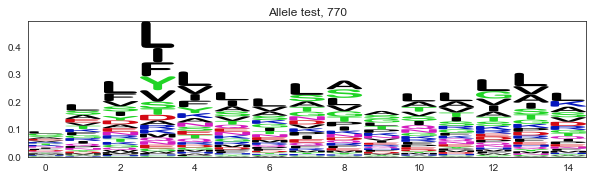

In [62]:
make_logo_for_data(peptides, "test")

In [63]:
cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
         

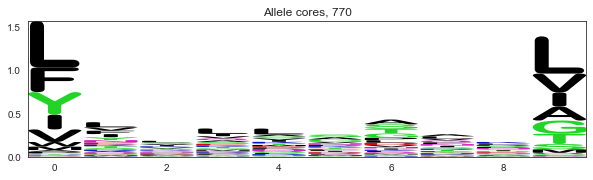

In [64]:
make_logo_for_data(cores, "cores")

# Construct model with joiners where joiners are selected

In [65]:
dict(sorted(selected_labels_and_groups.items(), key=lambda x:x[1]))

{0: 2, 7: 4, 4: 5, 1: 7}

In [66]:
set(selected_labels_and_groups.values())

{2, 4, 5, 7}

In [67]:
joiner_positions = {i: [label for label, group in selected_labels_and_groups.items() if  group == original_position] for i,original_position in enumerate(sorted(set(selected_labels_and_groups.values())))}
joiner_positions

{0: [0], 1: [7], 2: [4], 3: [1]}

In [68]:
selected_labels_to_distr = labels_to_distr.loc[selected_labels_and_groups.keys()]

In [69]:

joiner_distributions = selected_labels_to_distr.to_dict(orient='index')


In [70]:
%load_ext autoreload
%autoreload 2

In [71]:

from hmm_logic_methods import init_grouped_structure_model_with_predefined_joiners_and_cycles

model = init_grouped_structure_model_with_predefined_joiners_and_cycles(joiner_positions, joiner_parameters=joiner_distributions, states_per_group=[ 5, 5, 5], freeze_distr=False)

grouped_model : grouped_model-start summed to 2.0, normalized to 1.0
grouped_model : s000 summed to 17.0, normalized to 1.0
grouped_model : s001 summed to 17.0, normalized to 1.0
grouped_model : s002 summed to 17.0, normalized to 1.0
grouped_model : s003 summed to 17.0, normalized to 1.0
grouped_model : s004 summed to 17.0, normalized to 1.0
grouped_model : s005 summed to 17.0, normalized to 1.0
grouped_model : s006 summed to 17.0, normalized to 1.0
grouped_model : s007 summed to 17.0, normalized to 1.0
grouped_model : s008 summed to 17.0, normalized to 1.0
grouped_model : s009 summed to 17.0, normalized to 1.0
grouped_model : s010 summed to 17.0, normalized to 1.0
grouped_model : s011 summed to 17.0, normalized to 1.0
grouped_model : s012 summed to 17.0, normalized to 1.0
grouped_model : s013 summed to 17.0, normalized to 1.0
grouped_model : s014 summed to 17.0, normalized to 1.0
grouped_model : s015 summed to 5.0, normalized to 1.0
grouped_model : s016 summed to 8.0, normalized to 1.

In [72]:
with open('model.png', 'w+') as f:
    model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [73]:
from hmm_visualization_methods import *
plot_distributions_for_states(model,"test/", horizontal=False)

in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormal

In [74]:
make_pyviz_graph(model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
i

<class 'pyvis.network.Network'> |N|=23 |E|=98

In [75]:
stop_threshold

11.744135802469136

## Prepare models for training

In [76]:
# Training params
algorithm = 'baum-welch'

params = dict()
params['states_per_group'] = [5, 5, 5]
if type(params['states_per_group']) == int:
    params['st'] = len(joiner_distributions) + params['states_per_group']*len(joiner_positions) + 2
else:
    params['st'] = len(joiner_distributions) + sum(params['states_per_group']) + 2
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 5
params['max_iters'] = 70
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 0
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0.25
params['distribution_inertia'] = 0

#BACKUP
# params['emission_pseudocount'] = 1
# params['transition_pseudocount'] = 0
# params['verbose'] = True
# params['lr_decay'] = 0
# params['edge_inertia'] = 0.25
# params['distribution_inertia'] = 0


params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

In [77]:
joiner_positions

{0: [0], 1: [7], 2: [4], 3: [1]}

In [78]:
len(joiner_distributions)

4

In [79]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_with_predefined_joiners_and_cycles(joiner_positions, joiner_parameters=joiner_distributions, states_per_group=params['states_per_group'], freeze_distr=False)
            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

grouped_model : grouped_model-start summed to 2.0, normalized to 1.0
grouped_model : s000 summed to 17.0, normalized to 1.0
grouped_model : s001 summed to 17.0, normalized to 1.0
grouped_model : s002 summed to 17.0, normalized to 1.0
grouped_model : s003 summed to 17.0, normalized to 1.0
grouped_model : s004 summed to 17.0, normalized to 1.0
grouped_model : s005 summed to 17.0, normalized to 1.0
grouped_model : s006 summed to 17.0, normalized to 1.0
grouped_model : s007 summed to 17.0, normalized to 1.0
grouped_model : s008 summed to 17.0, normalized to 1.0
grouped_model : s009 summed to 17.0, normalized to 1.0
grouped_model : s010 summed to 17.0, normalized to 1.0
grouped_model : s011 summed to 17.0, normalized to 1.0
grouped_model : s012 summed to 17.0, normalized to 1.0
grouped_model : s013 summed to 17.0, normalized to 1.0
grouped_model : s014 summed to 17.0, normalized to 1.0
grouped_model : s015 summed to 5.0, normalized to 1.0
grouped_model : s016 summed to 8.0, normalized to 1.

In [80]:
len(joiner_distributions)

4

In [81]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_with_predefined_joiners_and_cycles(joiner_positions, joiner_parameters=joiner_distributions, states_per_group=params['states_per_group'], freeze_distr=False)
            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

grouped_model : grouped_model-start summed to 2.0, normalized to 1.0
grouped_model : s000 summed to 17.0, normalized to 1.0
grouped_model : s001 summed to 17.0, normalized to 1.0
grouped_model : s002 summed to 17.0, normalized to 1.0
grouped_model : s003 summed to 17.0, normalized to 1.0
grouped_model : s004 summed to 17.0, normalized to 1.0
grouped_model : s005 summed to 17.0, normalized to 1.0
grouped_model : s006 summed to 17.0, normalized to 1.0
grouped_model : s007 summed to 17.0, normalized to 1.0
grouped_model : s008 summed to 17.0, normalized to 1.0
grouped_model : s009 summed to 17.0, normalized to 1.0
grouped_model : s010 summed to 17.0, normalized to 1.0
grouped_model : s011 summed to 17.0, normalized to 1.0
grouped_model : s012 summed to 17.0, normalized to 1.0
grouped_model : s013 summed to 17.0, normalized to 1.0
grouped_model : s014 summed to 17.0, normalized to 1.0
grouped_model : s015 summed to 5.0, normalized to 1.0
grouped_model : s016 summed to 8.0, normalized to 1.

In [82]:
prepared_model.name

'4_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0'

# Do actual training

In [83]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model


In [84]:
TARGET_PATH_TO_RESULTS = TARGET_PATH_TO_RESULTS + "anchor_models/"

In [85]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'])
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)

run 0
split 0
train size 12667
Shuffling for fairness 
Simple training: Train Length 12667, init_batch_size None
[1] Improvement: -1859177.7369458475	Time (s): 3.016
[2] Improvement: 32742.238293259405	Time (s): 3.013
[3] Improvement: 8006.827511137351	Time (s): 3.918
[4] Improvement: 4100.797746603377	Time (s): 3.073
[5] Improvement: 2886.397566673346	Time (s): 2.812
[6] Improvement: 2345.2404002361	Time (s): 2.755
[7] Improvement: 2047.4589553317055	Time (s): 3.952
[8] Improvement: 1858.5694285826758	Time (s): 2.784
[9] Improvement: 1727.999732149765	Time (s): 2.765
[10] Improvement: 1633.8290788121521	Time (s): 2.785
[11] Improvement: 1564.3970061177388	Time (s): 3.5
[12] Improvement: 1511.5285122701898	Time (s): 2.775
[13] Improvement: 1468.453802432865	Time (s): 2.707
[14] Improvement: 1429.803727238439	Time (s): 2.855
[15] Improvement: 1392.1767224930227	Time (s): 3.027
[16] Improvement: 1354.3669953104109	Time (s): 2.632
[17] Improvement: 1316.9740821011364	Time (s): 2.673
[18] 

In [86]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
3
4
Wall time: 2.57 s


In [87]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False)
    print(i)

0
1
2
3
4
Wall time: 43.9 s


In [88]:
from hmm_visualization_methods import *
per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (1_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (2_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (3_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (4_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)


# Check new model in a similar way!

In [89]:
core_start_state= 15
core_end_state = 16

In [91]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


In [92]:
per_model_anchors = dict()
for model_key, model in per_name_models.items():
    per_model_anchors[model_key] = dict()
    per_model_anchors[model_key]['max'] = model.states[core_end_state].name
    per_model_anchors[model_key]['min'] = model.states[core_start_state].name
    

In [93]:
per_model_anchors

{'0_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': 's016',
  'min': 's015'},
 '1_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': 's016',
  'min': 's015'},
 '2_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': 's016',
  'min': 's015'},
 '3_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': 's016',
  'min': 's015'},
 '4_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': 's016',
  'min': 's015'}}

In [94]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [95]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_models.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides,
                                                                                   start_states=per_model_anchors[model_key]['min'],
                                                                                   end_states=per_model_anchors[model_key]['max'])
    result_df[f'core_start_{i}'] = viterbi_paths['core_start'].values
    result_df[f'core_end_{i}'] = viterbi_paths['core_end'].values
    result_df[f'v_prob_{i}'] = viterbi_paths['viterbi_probs'].values
    
    
    #find anchor for each model
    

Model 0_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at s015 and ends at s016
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 15133.80it/s]


Model 1_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at s015 and ends at s016
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:01<00:00, 12591.72it/s]


Model 2_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at s015 and ends at s016
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14660.89it/s]


Model 3_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at s015 and ends at s016
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 13620.53it/s]


Model 4_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at s015 and ends at s016
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 15428.77it/s]


In [96]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4
LGVLESDLPS,0,7,-32.738971,0,7,-32.569657,1,9,-32.378370,0,8,-32.712313,0,7,-33.087519
YSKTQKLGKS,0,8,-33.199871,0,8,-33.802748,0,7,-36.938137,1,9,-37.134963,1,9,-35.369823
LKAVPSQKRT,0,9,-31.865296,0,8,-31.780559,1,9,-34.324908,1,8,-31.997651,1,8,-31.905012
KRWIILGLNK,2,9,-36.315415,1,9,-36.094288,1,9,-35.907256,1,9,-35.223046,1,9,-35.299723
HAVSEGTKAV,1,9,-31.326116,1,9,-32.427559,1,8,-31.501751,1,9,-33.422039,1,8,-32.685175
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,4,12,-56.620784,3,12,-54.849768,3,12,-55.977840,3,12,-56.413682,3,12,-55.448436
AVPGKTFVSITPAEVGVL,6,16,-53.268727,6,14,-54.387142,5,14,-53.610329,5,14,-52.779480,5,14,-52.656330
VPHLRYLRLDGNYLKPPI,5,14,-55.589469,3,13,-55.339967,4,13,-54.833925,4,14,-53.781736,4,13,-53.935050
DIRRFDPIPAQYVRVYPE,4,14,-58.450810,4,12,-57.151465,3,12,-56.908535,3,12,-57.067797,3,12,-56.338080


In [97]:
result_df['len'] = result_df.index.str.len()

In [98]:
result_df[result_df['len']==15]

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
IVLSSELRLSHSRTH,0,9,-49.215237,0,8,-48.289477,5,13,-47.946538,5,13,-48.812605,5,13,-49.817349,15
MDNDLAATNDHNVME,4,12,-52.112496,4,12,-51.788990,3,12,-53.662284,3,13,-53.474655,3,13,-53.040158,15
EFHLDGEVLSLDKLK,1,8,-44.468403,1,8,-45.688769,0,8,-45.649829,0,9,-46.006181,0,8,-45.812271,15
SPSIVIALAGNKADL,3,12,-43.587965,3,12,-42.743359,4,12,-43.306253,3,12,-42.970281,3,12,-42.804065,15
ERSLWIIFSKNLNIK,3,11,-48.530112,3,11,-48.216759,3,11,-48.786541,2,11,-48.730898,2,11,-48.206189,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,1,9,-50.092977,3,12,-49.737051,3,12,-49.938642,3,12,-48.459705,3,12,-49.139440,15
ETQYSEMFGMVLAPA,3,12,-48.668162,3,11,-46.446048,2,11,-46.763742,2,12,-44.880959,2,11,-45.035752,15
FNMVYMPASWVMRIM,2,10,-55.992802,2,10,-53.624053,2,10,-54.018430,2,10,-53.917092,1,11,-53.980022,15
IFLSKDLQADIKGRD,1,10,-48.334160,0,8,-50.491448,1,8,-48.694771,0,8,-47.560531,0,8,-48.070568,15


In [100]:
peptide = 'IVLSSELRLSHSRTH'

model = per_name_models['0_run-10-11-12-13-14-15-16-17-18-21-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0']

In [101]:
pd.DataFrame(model.forward_backward(peptide)[1])

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-0.789694,-inf,-inf,-inf,-0.605107,-inf
1,-1.646926,-3.578107,-1.483482,-5.461112,-6.066697,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-2.173715,-inf,-inf,-inf,-0.838723,-inf
2,-4.034350,-2.273412,-2.586970,-3.893051,-5.100313,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-2.030557,-inf,-inf,-1.063183,-1.200646,-inf
3,-2.861670,-3.139928,-2.576660,-5.567643,-4.464592,-1.770207,-3.103381,-3.241195,-4.300599,-2.557703,...,-inf,-inf,-inf,-inf,-5.511186,-inf,-inf,-1.821209,-1.214164,-inf
4,-6.003287,-2.060987,-6.221574,-7.218382,-4.630465,-1.990192,-6.098846,-3.643214,-2.703198,-3.056882,...,-inf,-inf,-inf,-inf,-4.483184,-inf,-1.478071,-2.926419,-1.252950,-inf
5,-4.745482,-6.022037,-5.612811,-7.309137,-6.756985,-4.214271,-5.248898,-6.876736,-5.121285,-3.417826,...,-8.744760,-5.421780,-2.254677,-2.669472,-1.961660,-inf,-1.298736,-1.988015,-1.930772,-inf
6,-4.106590,-6.660470,-2.235619,-3.871163,-6.582943,-7.964581,-2.041782,-4.587998,-8.408399,-6.566292,...,-2.454820,-4.199773,-2.682942,-1.245403,-1.946889,-3.478903,-2.903355,-4.572210,-6.066758,-inf
7,-2.674667,-1.991533,-2.837014,-5.600883,-3.924683,-2.338331,-8.893241,-6.063040,-4.040946,-3.921073,...,-2.863254,-1.536751,-3.117695,-4.884962,-6.083265,-2.936047,-4.139601,-6.143959,-10.178961,-3.478903
8,-7.430688,-3.316743,-6.242740,-7.680914,-6.265904,-10.401786,-4.858445,-3.533833,-6.852334,-9.548850,...,-1.033908,-6.685161,-4.696239,-4.092163,-10.178961,-2.277146,-2.298730,-1.392030,-inf,-2.477935
9,-10.918214,-8.970298,-11.297742,-14.650702,-11.333353,-1.949217,-3.478739,-3.792783,-4.020957,-2.970585,...,-4.177090,-4.548657,-2.913084,-3.260535,-inf,-1.031135,-3.829958,-3.193268,-inf,-1.679362


In [102]:
prob, path = model.viterbi(peptide)

In [103]:
[item[0] for item in path]

[21, 15, 2, 1, 18, 5, 17, 14, 12, 11, 16, 20, 20, 20, 20, 20, 22]

In [104]:
peptide

'IVLSSELRLSHSRTH'

In [105]:
prob, path = model.maximum_a_posteriori([i for i in peptide])


In [106]:
[item[0] for item in path]

[19, 19, 18, 19, 19, 17, 14, 12, 11, 16, 20, 20, 20, 20, 20]

In [107]:
pd.set_option('display.max_columns', 500)
pd.DataFrame(model.forward(peptide))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-4.942558,-inf,-inf,-inf,-3.309783,-inf,-inf,-inf
2,-8.198835,-11.241052,-7.745456,-11.237267,-13.362645,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-7.350720,-inf,-inf,-inf,-6.550286,-inf,-inf,-inf
3,-11.776311,-10.895072,-10.129915,-11.501900,-13.415165,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-9.739947,-inf,-inf,-9.920404,-9.794934,-inf,-inf,-inf
4,-13.432493,-12.441583,-13.354943,-15.962903,-14.589012,-13.123805,-15.293222,-14.993475,-15.662005,-14.022772,-inf,-inf,-inf,-inf,-inf,-15.186404,-inf,-inf,-13.907706,-12.629511,-inf,-inf,-inf
5,-18.597183,-15.342569,-18.618193,-20.256788,-17.691696,-16.860311,-19.179478,-17.723696,-17.591968,-17.781981,-inf,-inf,-inf,-inf,-inf,-18.020981,-inf,-14.903991,-15.686801,-15.464088,-inf,-inf,-inf
6,-20.676758,-22.702655,-21.050018,-24.405067,-23.276303,-20.246349,-19.371414,-22.319028,-21.186570,-19.306173,-19.037666,-24.407290,-21.548113,-18.104075,-18.305853,-19.949551,-inf,-19.319534,-17.489047,-18.462814,-inf,-inf,-inf
7,-24.380785,-23.826302,-22.731278,-24.112263,-26.172066,-25.970506,-19.760267,-22.283002,-26.436315,-24.463127,-23.144476,-19.607007,-23.292562,-22.416457,-21.687596,-21.652474,-20.794896,-23.055407,-22.437435,-21.707461,-inf,-inf,-22.639223
8,-25.088964,-25.478876,-24.998130,-27.211902,-27.053140,-22.875183,-30.059484,-27.544543,-24.791171,-24.536774,-24.869881,-25.073763,-24.584236,-25.883700,-27.130809,-26.665121,-23.445979,-26.196432,-28.816075,-25.110978,-23.563484,-inf,-24.029250
9,-30.820461,-28.001053,-29.197499,-29.926680,-30.539775,-36.049485,-29.727714,-28.635860,-32.524314,-35.092156,-30.670009,-25.804048,-31.340317,-29.192645,-28.329450,-28.300638,-26.234199,-26.732323,-26.073769,-28.355625,-26.009637,-inf,-26.561057


In [108]:
pd.DataFrame(model.backward(peptide))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
0,-44.521940,-46.961144,-44.618065,-43.994811,-45.267055,-50.567608,-49.586303,-49.881739,-50.490789,-50.679000,-49.738459,-51.002278,-49.486373,-49.205604,-49.030401,-43.626754,-52.665185,-48.382162,-48.669353,-44.659525,-53.090536,-45.317440,-inf
1,-40.775657,-41.726732,-40.532792,-40.932097,-41.068302,-45.912255,-45.199084,-45.522061,-45.813178,-45.894817,-45.543723,-46.597660,-45.355620,-45.311615,-45.440021,-41.164575,-48.540714,-45.140355,-44.626073,-42.612763,-48.966065,-42.477429,-inf
2,-38.765531,-37.654495,-39.055465,-39.541285,-38.021492,-42.762470,-41.111149,-39.868549,-42.058097,-42.236473,-42.190129,-42.972867,-42.092995,-42.370137,-42.806011,-40.140435,-44.686629,-42.202599,-38.573613,-39.605877,-45.111980,-39.564022,-inf
3,-37.575478,-36.695779,-37.774494,-37.708591,-37.002588,-37.732039,-36.323444,-37.096525,-37.633366,-37.472348,-39.981273,-40.408558,-39.914040,-40.015984,-39.912797,-37.608050,-41.239507,-39.866027,-36.460218,-36.723152,-41.664858,-36.420217,-inf
4,-34.746616,-36.015785,-34.539157,-34.922180,-35.193020,-33.963842,-33.127599,-33.565160,-33.956034,-33.852371,-37.130112,-37.122805,-37.120543,-36.935553,-36.136521,-35.642221,-37.988621,-35.831809,-33.230942,-33.902092,-38.413972,-33.618839,-inf
5,-32.723544,-32.035858,-32.920821,-32.279034,-32.256209,-30.447321,-32.236808,-31.236957,-30.428670,-30.592341,-33.278398,-34.921235,-32.973946,-32.717945,-32.481798,-31.779642,-34.737734,-31.891519,-32.557058,-31.106301,-35.163085,-31.279963,-inf
6,-29.386164,-28.636822,-29.880232,-28.221509,-28.798121,-29.285361,-31.194923,-29.875148,-29.252154,-29.429093,-29.289556,-29.654909,-29.191107,-29.468042,-29.681059,-27.329549,-31.448568,-27.296642,-29.816407,-28.785398,-31.873919,-29.945262,-inf
7,-25.043244,-28.151608,-24.821781,-25.076339,-25.728317,-27.311515,-27.598954,-27.622436,-27.289524,-27.420604,-26.512058,-28.165252,-26.224651,-25.583925,-24.875247,-25.611854,-28.001446,-25.165388,-27.452214,-29.676736,-28.426797,-30.835285,-inf
8,-22.903143,-21.830097,-23.156324,-23.706421,-22.188982,-24.780587,-24.151197,-23.835936,-24.567215,-24.701739,-22.358802,-23.106931,-22.269954,-22.551435,-23.071592,-24.735583,-24.807508,-23.260608,-22.645323,-30.385423,-25.232859,-31.601489,-inf
9,-21.927667,-20.633130,-22.362680,-23.071673,-21.043569,-19.669741,-20.448171,-20.215413,-19.645459,-19.774133,-20.626017,-20.547299,-20.662284,-20.821034,-21.080152,-27.195762,-21.360386,-20.883846,-20.635700,-inf,-21.785737,-inf,-inf


In [109]:
'LALYQPANKHYIHCF'[2:12]

'LYQPANKHYI'

In [110]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
LGVLESDLPS,0,7,-32.738971,0,7,-32.569657,1,9,-32.378370,0,8,-32.712313,0,7,-33.087519,10
YSKTQKLGKS,0,8,-33.199871,0,8,-33.802748,0,7,-36.938137,1,9,-37.134963,1,9,-35.369823,10
LKAVPSQKRT,0,9,-31.865296,0,8,-31.780559,1,9,-34.324908,1,8,-31.997651,1,8,-31.905012,10
KRWIILGLNK,2,9,-36.315415,1,9,-36.094288,1,9,-35.907256,1,9,-35.223046,1,9,-35.299723,10
HAVSEGTKAV,1,9,-31.326116,1,9,-32.427559,1,8,-31.501751,1,9,-33.422039,1,8,-32.685175,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,4,12,-56.620784,3,12,-54.849768,3,12,-55.977840,3,12,-56.413682,3,12,-55.448436,18
AVPGKTFVSITPAEVGVL,6,16,-53.268727,6,14,-54.387142,5,14,-53.610329,5,14,-52.779480,5,14,-52.656330,18
VPHLRYLRLDGNYLKPPI,5,14,-55.589469,3,13,-55.339967,4,13,-54.833925,4,14,-53.781736,4,13,-53.935050,18
DIRRFDPIPAQYVRVYPE,4,14,-58.450810,4,12,-57.151465,3,12,-56.908535,3,12,-57.067797,3,12,-56.338080,18


In [111]:
result_df['core_length'] = result_df['core_end_0'] + 1 - result_df['core_start_0']

In [112]:
result_df['core_length'].value_counts()

9     5641
10    4891
11    1099
8      822
12     155
7       47
13      12
Name: core_length, dtype: int64

In [113]:
result_df[result_df['len'] == 15]['core_length'].value_counts()

9     2954
10    2548
11     708
8      533
12     106
7       32
13       5
Name: core_length, dtype: int64

In [1]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 11] 

NameError: name 'result_df' is not defined

In [ ]:
peptides = df.index.values 
core_starts = df['core_start_0'].values
core_ends = df['core_end_0'].values


In [2]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

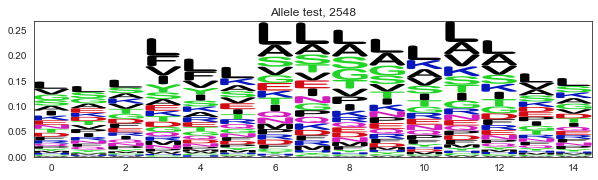

In [120]:
make_logo_for_data(peptides, "test")

In [121]:
cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
         

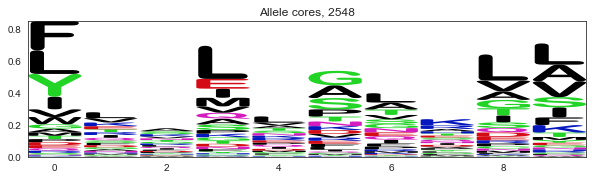

In [122]:
make_logo_for_data(cores, "cores")

## Forward-Backward estimate to find core

In [123]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_models.items()):
    core_starts = list()
    core_ends = list()
    for peptide in allele_peptides:
        fb_result = model.forward_backward(peptide)[1]
        arg_min = fb_result.argmax(axis=0)
        min_position = arg_min[core_start_state]
        max_position = arg_min[core_end_state]
        # assert min_position < max_position
        core_starts.append(min_position)
        core_ends.append(max_position)
    
    result_df[f'core_start_{i}'] = core_starts
    result_df[f'core_end_{i}'] = core_ends


In [124]:
result_df['len'] = result_df.index.str.len()
result_df['core_length'] = result_df['core_end_0'] + 1 - result_df['core_start_0']

In [125]:
result_df['core_length'].value_counts()

9     4855
10    4609
11    1577
8      642
12     612
13     206
14      77
7       44
15      16
6       11
4        7
17       5
16       3
5        2
3        1
Name: core_length, dtype: int64

In [126]:
result_df[result_df['len'] == 15]['core_length'].value_counts()

10    2395
9     2312
11    1071
12     425
8      410
13     166
14      59
7       24
6        9
15       7
4        6
5        2
Name: core_length, dtype: int64

In [127]:
result_df[result_df['len'] == 15]

,core_start_0,core_end_0,core_start_1,core_end_1,core_start_2,core_end_2,core_start_3,core_end_3,core_start_4,core_end_4,len,core_length
IVLSSELRLSHSRTH,0,9,0,8,5,13,5,13,5,13,15,10
MDNDLAATNDHNVME,4,12,4,12,3,12,3,13,3,13,15,9
EFHLDGEVLSLDKLK,1,8,1,8,0,8,0,9,0,8,15,8
SPSIVIALAGNKADL,3,12,3,12,4,12,3,12,3,12,15,10
ERSLWIIFSKNLNIK,3,11,3,11,3,11,2,11,2,11,15,9
...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,1,12,1,12,3,12,3,12,3,12,15,12
ETQYSEMFGMVLAPA,3,12,3,11,2,11,2,12,2,11,15,10
FNMVYMPASWVMRIM,2,10,2,10,2,10,2,10,1,11,15,9
IFLSKDLQADIKGRD,1,11,0,8,1,8,0,8,0,8,15,11


In [134]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 9] 

In [135]:
peptides = df.index.values 
core_starts = df['core_start_0'].values
core_ends = df['core_end_0'].values


In [136]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

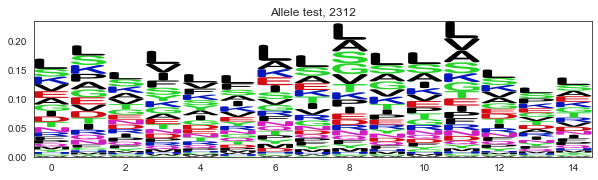

In [137]:
make_logo_for_data(peptides, "test")

In [138]:
cores = [peptide[core_starts[i]+1:core_ends[i]] for i,peptide in enumerate(peptides)]
         

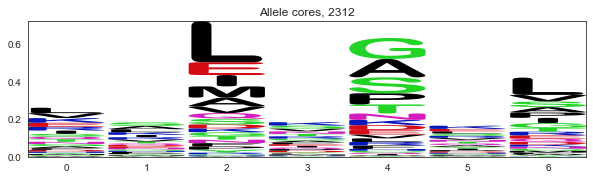

In [139]:
make_logo_for_data(cores, "cores")

In [159]:
df

,core_start_0,core_end_0,core_start_1,core_end_1,core_start_2,core_end_2,core_start_3,core_end_3,core_start_4,core_end_4,len,core_length
LSYRSLQPETFAVVD,2,12,5,13,2,9,2,9,2,9,15,11
LLKDVEYARPGLISS,1,11,6,12,4,12,1,12,1,12,15,11
ELLGVEPPSESDLEF,2,12,2,10,2,12,2,12,2,8,15,11
FGLSYKEQVGSNREL,4,14,4,14,4,14,4,14,4,14,15,11
DTFRKLFDVYSNFLR,2,12,6,13,6,13,2,13,2,13,15,11
...,...,...,...,...,...,...,...,...,...,...,...,...
REKLQAANAEDIKSG,1,11,3,11,3,11,3,11,3,10,15,11
YKFIPSLEAAVKQAY,0,10,3,10,0,10,2,10,2,10,15,11
LLESDHLISEILSRE,1,11,4,10,1,11,1,11,1,11,15,11
KLRDLNKEVDRLMSM,1,11,1,11,4,11,1,11,1,11,15,11


# Another approach to find anchors -- distribution distances

<AxesSubplot:>

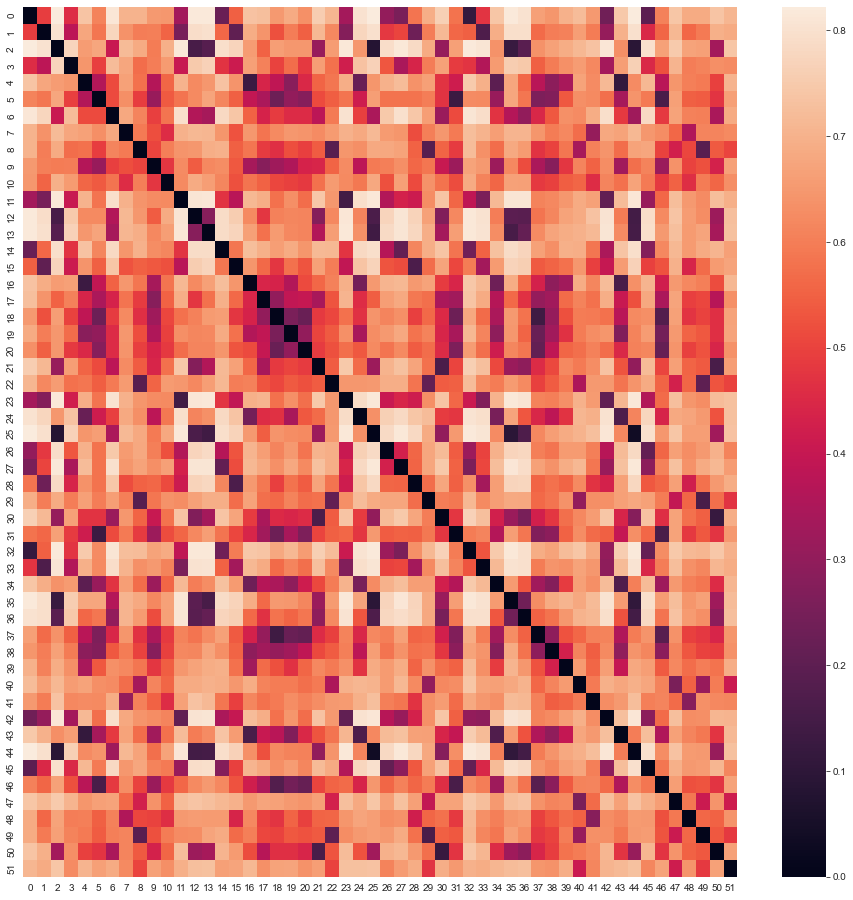

In [52]:
from scipy.special import rel_entr
from scipy.spatial.distance import pdist, squareform
dm = squareform(pdist(values_to_run_pca_on, lambda u, v: sum(rel_entr(u,v))))
dm = squareform(pdist(values_to_run_pca_on,metric='jensenshannon'))

fig, ax = plt.subplots(figsize=(16, 16))
sns.heatmap(dm)

In [372]:
df = pd.DataFrame(dm)
df['model'] = total_df['model'].values

In [373]:
lut = dict(zip(set(df['model']), sns.hls_palette(len(set(df['model'])), l=0.5, s=0.8)))

In [374]:
row_colors = df['model'].map(lut)

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\seaborn\matrix.py:624: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


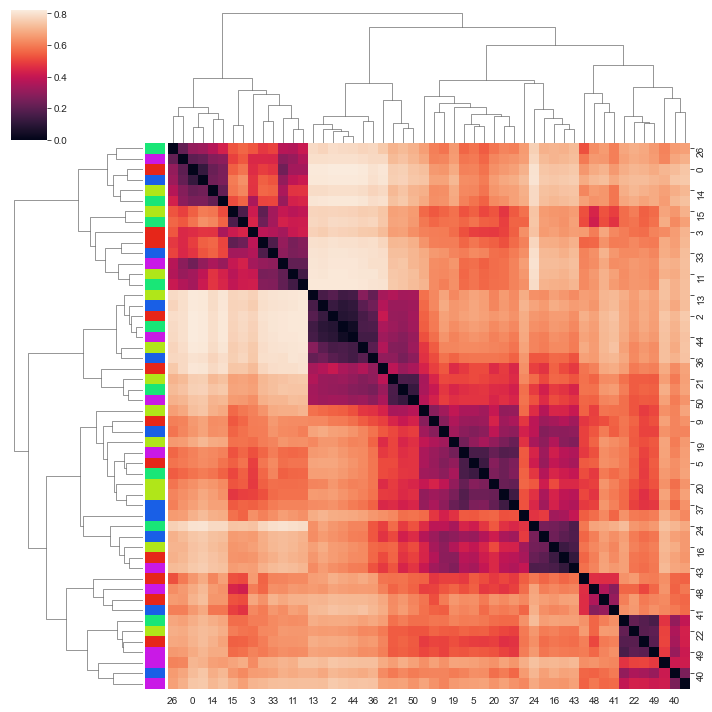

In [375]:

sns.clustermap(dm, row_colors=row_colors.to_numpy(), cmap='rocket')

## Calculate viterbi paths for train data (Try to find anchors)

In [49]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [51]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences
allele_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(model, allele_peptides)


Model 0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12667/12667 [00:01<00:00, 10292.21it/s]


Select unique paths...
	Unique paths: 11714


100%|██████████| 11714/11714 [00:00<00:00, 35700.07it/s]


In [52]:
allele_bw_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s001>s005>s014>s013>s015>s...,-10.002307,-0.714451,12,-34.795086,3
1,grouped_model-start>s003>s007>s005>s014>s013>s...,-10.791529,-0.719435,13,-42.684984,1
2,grouped_model-start>s004>s009>s007>s005>s014>s...,-11.579876,-0.723742,14,-39.344564,1
3,grouped_model-start>s003>s007>s005>s014>s013>s...,-10.877871,-0.725191,13,-36.525293,2
4,grouped_model-start>s000>s001>s005>s014>s013>s...,-10.894956,-0.726330,13,-37.903886,1
...,...,...,...,...,...,...
11709,grouped_model-start>s000>s009>s012>s017>s023>s...,-27.080313,-1.592960,15,-53.481328,1
11710,grouped_model-start>s003>s008>s014>s011>s018>s...,-27.232899,-1.601935,15,-54.368034,1
11711,grouped_model-start>s002>s000>s002>s001>s006>s...,-27.282463,-1.604851,15,-59.117454,1
11712,grouped_model-start>s003>s004>s009>s007>s008>s...,-28.499659,-1.676451,15,-56.238231,1


In [66]:
state_names = [f"s{i:03d}".format(i) for i in range(len(model.states) - 2)] # minus start minus end

# allele_bw_paths_df.loc[:,state_names] = 0

per_state_counts = dict()

In [67]:
for state_name in state_names:
    per_state_counts[state_name] =  allele_bw_paths_df[allele_bw_paths_df['path'].str.contains(state_name)]['peptide_cnts'].sum()


In [68]:
per_state_counts

{'s000': 4215,
 's001': 4885,
 's002': 3780,
 's003': 2513,
 's004': 5635,
 's005': 6680,
 's006': 2045,
 's007': 6424,
 's008': 3834,
 's009': 3114,
 's010': 2078,
 's011': 2275,
 's012': 2398,
 's013': 8064,
 's014': 8126,
 's015': 6469,
 's016': 2003,
 's017': 1406,
 's018': 1941,
 's019': 2266,
 's020': 8900,
 's021': 5908,
 's022': 1625,
 's023': 3999,
 's024': 1478,
 's025': 722,
 's026': 1966,
 's027': 5314,
 's028': 2436,
 's029': 3851,
 's030': 7591,
 's031': 1568,
 's032': 6300,
 's033': 2569,
 's034': 3135,
 's035': 3362,
 's036': 4899,
 's037': 3494,
 's038': 8420,
 's039': 2492,
 's040': 5131,
 's041': 2712,
 's042': 5215,
 's043': 4777,
 's044': 7069}

In [69]:
import seaborn as sns

In [84]:
df = pd.DataFrame.from_dict(per_state_counts, orient='index', columns=['cnt'])

# sns.barplot(x=list(per_state_counts.keys()), y=list(per_state_counts.values()))

<AxesSubplot:>

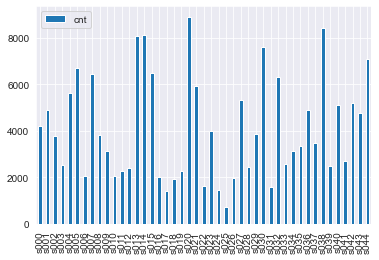

In [85]:
df.plot(kind='bar')

In [87]:
df.sort_values(by='cnt', ascending=False)

,cnt
s020,8900
s038,8420
s014,8126
s013,8064
s030,7591
s044,7069
s005,6680
s015,6469
s007,6424
s032,6300


In [88]:
model.dense_transition_matrix()

array([[0.        , 0.18783749, 0.24838837, ..., 0.        , 0.        ,
        0.        ],
       [0.02338106, 0.        , 0.08356533, ..., 0.        , 0.        ,
        0.        ],
       [0.10202855, 0.22541672, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.70792018],
       [0.24782062, 0.12390521, 0.03135931, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])